In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42

In [4]:
df = pd.read_csv(r"D:\Applications\MLops-OList dataset\sentinelml-network-intrusion-detection\notebooks\data\raw\rt_iot2022.csv")

print("Original dataset shape:", df.shape)
display(df.head())

Original dataset shape: (123117, 84)


,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,...,0.0,29729182.96,29729182.96,29729182.96,29729182.96,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,...,0.0,29855277.06,29855277.06,29855277.06,29855277.06,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,...,0.0,29842149.02,29842149.02,29842149.02,29842149.02,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,...,0.0,29913774.97,29913774.97,29913774.97,29913774.97,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,...,0.0,29814704.90,29814704.90,29814704.90,29814704.90,0.0,64240,26847,502,MQTT_Publish


In [5]:
feature_columns = [
    col for col in df.columns
    if col != "Attack_type"
]

group_labels = (
    df.groupby(feature_columns, dropna=False)["Attack_type"]
    .transform("nunique")
)

df_model = df.loc[group_labels == 1].copy()

print("Original shape:", df.shape)
print("Modeling dataset shape:", df_model.shape)

Original shape: (123117, 84)
Modeling dataset shape: (122989, 84)


In [6]:
X = df_model.drop(
    columns=["Attack_type", "bwd_URG_flag_count"]
)

y_multi = df_model["Attack_type"]

print("Feature shape:", X.shape)
print("Target shape:", y_multi.shape)

print("\nNumber of classes:", y_multi.nunique())
print("\nClasses:")
print(sorted(y_multi.unique()))

Feature shape: (122989, 82)
Target shape: (122989,)

Number of classes: 12

Classes:
['ARP_poisioning', 'DDOS_Slowloris', 'DOS_SYN_Hping', 'MQTT_Publish', 'Metasploit_Brute_Force_SSH', 'NMAP_FIN_SCAN', 'NMAP_OS_DETECTION', 'NMAP_TCP_scan', 'NMAP_UDP_SCAN', 'NMAP_XMAS_TREE_SCAN', 'Thing_Speak', 'Wipro_bulb']


In [8]:
manifest = pd.read_csv(
    "data/processed/split_manifest.csv"
)

train_idx = manifest.loc[
    manifest["split"] == "train",
    "original_index"
].astype(int).to_numpy()

val_idx = manifest.loc[
    manifest["split"] == "validation",
    "original_index"
].astype(int).to_numpy()

test_idx = manifest.loc[
    manifest["split"] == "test",
    "original_index"
].astype(int).to_numpy()

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y_multi.iloc[train_idx].copy()
y_val = y_multi.iloc[val_idx].copy()
y_test = y_multi.iloc[test_idx].copy()

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (78712, 82) (78712,)
Validation: (19679, 82) (19679,)
Testing: (24598, 82) (24598,)


In [9]:
assert len(X_train) == 78712
assert len(X_val) == 19679
assert len(X_test) == 24598

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

print("All multiclass split reconstruction checks passed!")

All multiclass split reconstruction checks passed!


In [10]:
class_distribution = (
    y_train.value_counts()
    .rename_axis("Attack_type")
    .reset_index(name="Count")
)

class_distribution["Percentage"] = (
    class_distribution["Count"]
    / len(y_train) * 100
)

display(class_distribution)

,Attack_type,Count,Percentage
0,DOS_SYN_Hping,60582,76.966663
1,Thing_Speak,5139,6.528865
2,ARP_poisioning,4932,6.265881
3,MQTT_Publish,2653,3.370515
4,NMAP_UDP_SCAN,1655,2.102602
5,NMAP_XMAS_TREE_SCAN,1287,1.635075
6,NMAP_OS_DETECTION,1280,1.626182
7,NMAP_TCP_scan,641,0.814361
8,DDOS_Slowloris,340,0.431954
9,Wipro_bulb,161,0.204543


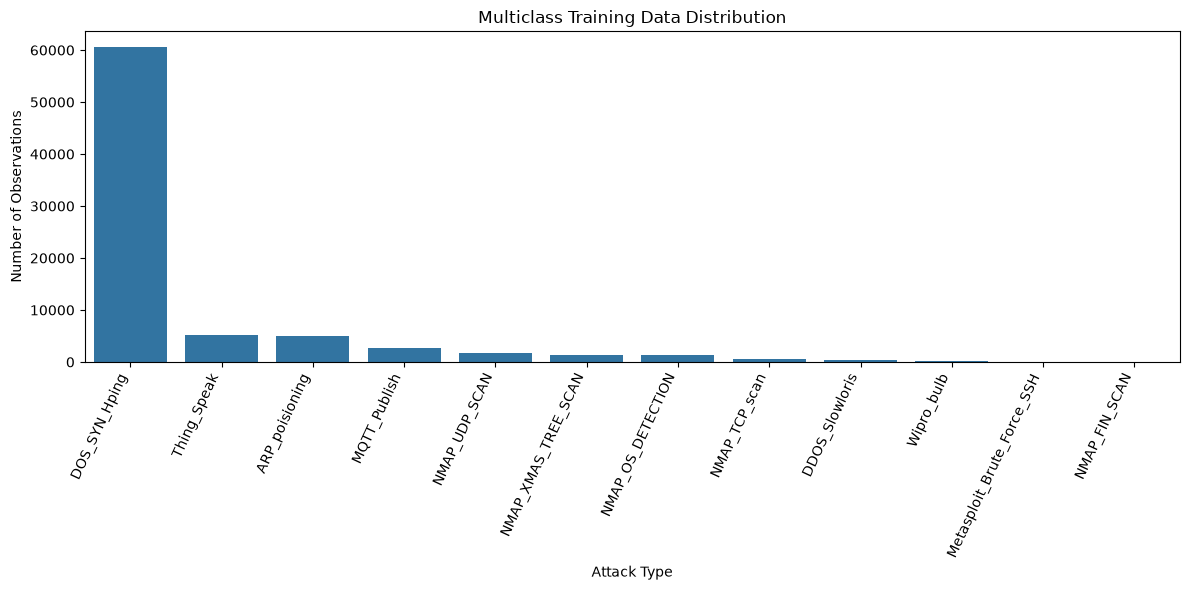

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=class_distribution,
    x="Attack_type",
    y="Count"
)

plt.xticks(rotation=65, ha="right")
plt.title("Multiclass Training Data Distribution")
plt.xlabel("Attack Type")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

In [12]:
split_distribution = pd.DataFrame({
    "Train": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Test": y_test.value_counts()
}).fillna(0).astype(int)

split_distribution["Total"] = split_distribution.sum(axis=1)

display(
    split_distribution.sort_values(
        by="Train",
        ascending=False
    )
)

,Train,Validation,Test,Total
Attack_type,,,,
DOS_SYN_Hping,60582,15145,18932,94659
Thing_Speak,5139,1285,1606,8030
ARP_poisioning,4932,1233,1541,7706
MQTT_Publish,2653,664,829,4146
NMAP_UDP_SCAN,1655,414,518,2587
NMAP_XMAS_TREE_SCAN,1287,321,402,2010
NMAP_OS_DETECTION,1280,320,400,2000
NMAP_TCP_scan,641,161,200,1002
DDOS_Slowloris,340,86,107,533


In [13]:
class_counts = y_train.value_counts()

majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = majority_count / minority_count

print("Majority class:", class_counts.idxmax())
print("Majority samples:", majority_count)

print("\nMinority class:", class_counts.idxmin())
print("Minority samples:", minority_count)

print("\nImbalance ratio:", round(imbalance_ratio, 2))

Majority class: DOS_SYN_Hping
Majority samples: 60582

Minority class: NMAP_FIN_SCAN
Minority samples: 19

Imbalance ratio: 3188.53


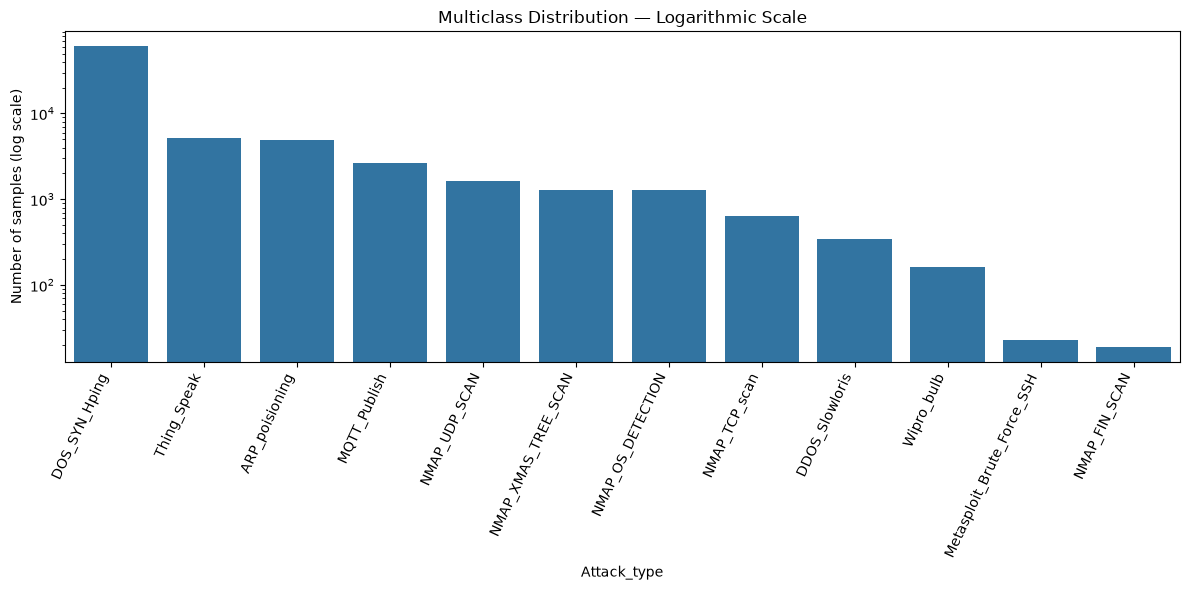

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.yscale("log")
plt.xticks(rotation=65, ha="right")
plt.ylabel("Number of samples (log scale)")
plt.title("Multiclass Distribution — Logarithmic Scale")
plt.tight_layout()
plt.show()

In [15]:
split_distribution = pd.DataFrame({
    "Train": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Test": y_test.value_counts()
}).fillna(0).astype(int)

split_distribution["Total"] = (
    split_distribution["Train"]
    + split_distribution["Validation"]
    + split_distribution["Test"]
)

display(
    split_distribution.sort_values(
        by="Train",
        ascending=False
    )
)

,Train,Validation,Test,Total
Attack_type,,,,
DOS_SYN_Hping,60582,15145,18932,94659
Thing_Speak,5139,1285,1606,8030
ARP_poisioning,4932,1233,1541,7706
MQTT_Publish,2653,664,829,4146
NMAP_UDP_SCAN,1655,414,518,2587
NMAP_XMAS_TREE_SCAN,1287,321,402,2010
NMAP_OS_DETECTION,1280,320,400,2000
NMAP_TCP_scan,641,161,200,1002
DDOS_Slowloris,340,86,107,533


In [16]:
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 80
Categorical features: 2

Categorical columns:
['proto', 'service']


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

preprocessor_tree = ColumnTransformer(
    transformers=[
        (
            "numerical",
            SimpleImputer(strategy="median"),
            numerical_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="most_frequent"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            categorical_features
        )
    ]
)

In [18]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print("Class mapping:")

for index, label in enumerate(label_encoder.classes_):
    print(index, ":", label)

print("\nNumber of classes:", len(label_encoder.classes_))

Class mapping:
0 : ARP_poisioning
1 : DDOS_Slowloris
2 : DOS_SYN_Hping
3 : MQTT_Publish
4 : Metasploit_Brute_Force_SSH
5 : NMAP_FIN_SCAN
6 : NMAP_OS_DETECTION
7 : NMAP_TCP_scan
8 : NMAP_UDP_SCAN
9 : NMAP_XMAS_TREE_SCAN
10 : Thing_Speak
11 : Wipro_bulb

Number of classes: 12


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [20]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )
}

In [21]:
baseline_results = []
baseline_predictions = {}
baseline_fitted_models = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor_tree),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train_encoded)

    predictions = pipeline.predict(X_val)

    baseline_fitted_models[model_name] = pipeline
    baseline_predictions[model_name] = predictions

    baseline_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_val_encoded, predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val_encoded, predictions
        ),
        "Macro F1": f1_score(
            y_val_encoded,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val_encoded,
            predictions,
            average="weighted",
            zero_division=0
        )
    })

baseline_comparison = pd.DataFrame(baseline_results)

display(
    baseline_comparison.sort_values(
        by="Macro F1",
        ascending=False
    ).round(6)
)


Training Decision Tree...

Training Random Forest...

Training XGBoost...


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
2,XGBoost,0.998526,0.951826,0.964870,0.998521
0,Decision Tree,0.997713,0.969613,0.956864,0.997721
1,Random Forest,0.997510,0.951288,0.952991,0.997524


In [22]:
for model_name, predictions in baseline_predictions.items():

    print("\n", "=" * 70)
    print(model_name)
    print("=" * 70)

    print(classification_report(
        y_val_encoded,
        predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    ))


Decision Tree
                            precision    recall  f1-score   support

            ARP_poisioning     0.9870    0.9838    0.9854      1233
            DDOS_Slowloris     1.0000    1.0000    1.0000        86
             DOS_SYN_Hping     1.0000    1.0000    1.0000     15145
              MQTT_Publish     1.0000    0.9985    0.9992       664
Metasploit_Brute_Force_SSH     0.8333    1.0000    0.9091         5
             NMAP_FIN_SCAN     0.6000    0.7500    0.6667         4
         NMAP_OS_DETECTION     1.0000    1.0000    1.0000       320
             NMAP_TCP_scan     1.0000    1.0000    1.0000       161
             NMAP_UDP_SCAN     0.9879    0.9879    0.9879       414
       NMAP_XMAS_TREE_SCAN     0.9938    1.0000    0.9969       321
               Thing_Speak     0.9860    0.9883    0.9872      1285
                Wipro_bulb     0.9744    0.9268    0.9500        41

                  accuracy                         0.9977     19679
                 macro avg     

In [23]:
for model_name in [
    "Decision Tree",
    "Random Forest",
    "XGBoost"
]:

    predictions = baseline_predictions[model_name]

    print("\n" + "=" * 75)
    print(model_name)
    print("=" * 75)

    print(classification_report(
        y_val_encoded,
        predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        digits=5,
        zero_division=0
    ))


Decision Tree
                            precision    recall  f1-score   support

            ARP_poisioning    0.98698   0.98378   0.98538      1233
            DDOS_Slowloris    1.00000   1.00000   1.00000        86
             DOS_SYN_Hping    1.00000   1.00000   1.00000     15145
              MQTT_Publish    1.00000   0.99849   0.99925       664
Metasploit_Brute_Force_SSH    0.83333   1.00000   0.90909         5
             NMAP_FIN_SCAN    0.60000   0.75000   0.66667         4
         NMAP_OS_DETECTION    1.00000   1.00000   1.00000       320
             NMAP_TCP_scan    1.00000   1.00000   1.00000       161
             NMAP_UDP_SCAN    0.98792   0.98792   0.98792       414
       NMAP_XMAS_TREE_SCAN    0.99381   1.00000   0.99689       321
               Thing_Speak    0.98602   0.98833   0.98717      1285
                Wipro_bulb    0.97436   0.92683   0.95000        41

                  accuracy                        0.99771     19679
                 macro avg    0

In [24]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils.class_weight import compute_sample_weight

classes = np.unique(y_train_encoded)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_encoded
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class weights:")

for class_id, weight in class_weight_dict.items():
    print(
        f"{label_encoder.classes_[class_id]}: {weight:.4f}"
    )

Class weights:
ARP_poisioning: 1.3300
DDOS_Slowloris: 19.2922
DOS_SYN_Hping: 0.1083
MQTT_Publish: 2.4724
Metasploit_Brute_Force_SSH: 285.1884
NMAP_FIN_SCAN: 345.2281
NMAP_OS_DETECTION: 5.1245
NMAP_TCP_scan: 10.2330
NMAP_UDP_SCAN: 3.9633
NMAP_XMAS_TREE_SCAN: 5.0966
Thing_Speak: 1.2764
Wipro_bulb: 40.7412


In [25]:
weighted_models = {
    "Weighted Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Weighted Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

In [26]:
weighted_results = []
weighted_predictions = {}
weighted_fitted_models = {}

for model_name, model in weighted_models.items():

    print(f"\nTraining {model_name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor_tree),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train_encoded)

    predictions = pipeline.predict(X_val)

    weighted_fitted_models[model_name] = pipeline
    weighted_predictions[model_name] = predictions

    weighted_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_val_encoded, predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val_encoded, predictions
        ),
        "Macro F1": f1_score(
            y_val_encoded,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val_encoded,
            predictions,
            average="weighted",
            zero_division=0
        )
    })

weighted_comparison = pd.DataFrame(weighted_results)

display(weighted_comparison.round(6))


Training Weighted Decision Tree...

Training Weighted Random Forest...


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Weighted Decision Tree,0.998323,0.949562,0.970367,0.998311
1,Weighted Random Forest,0.998323,0.952187,0.963509,0.998317


In [27]:
xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)

weighted_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

weighted_xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", weighted_xgb)
])

weighted_xgb_pipeline.fit(
    X_train,
    y_train_encoded,
    model__sample_weight=xgb_sample_weights
)

y_val_pred_weighted_xgb = weighted_xgb_pipeline.predict(X_val)

weighted_xgb_predictions = y_val_pred_weighted_xgb

weighted_xgb_metrics = {
    "Model": "Weighted XGBoost",
    "Accuracy": accuracy_score(
        y_val_encoded, weighted_xgb_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val_encoded, weighted_xgb_predictions
    ),
    "Macro F1": f1_score(
        y_val_encoded,
        weighted_xgb_predictions,
        average="macro",
        zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val_encoded,
        weighted_xgb_predictions,
        average="weighted",
        zero_division=0
    )
}

print(pd.Series(weighted_xgb_metrics))

Model                Weighted XGBoost
Accuracy                     0.998882
Balanced Accuracy            0.974625
Macro F1                     0.977468
Weighted F1                  0.998881
dtype: object


In [28]:
all_results = pd.concat([
    baseline_comparison,
    weighted_comparison,
    pd.DataFrame([weighted_xgb_metrics])
], ignore_index=True)

display(
    all_results.sort_values(
        by="Macro F1",
        ascending=False
    ).round(6)
)

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
5,Weighted XGBoost,0.998882,0.974625,0.977468,0.998881
3,Weighted Decision Tree,0.998323,0.949562,0.970367,0.998311
2,XGBoost,0.998526,0.951826,0.964870,0.998521
4,Weighted Random Forest,0.998323,0.952187,0.963509,0.998317
0,Decision Tree,0.997713,0.969613,0.956864,0.997721
1,Random Forest,0.997510,0.951288,0.952991,0.997524


In [29]:
print("WEIGHTED XGBOOST")

print(classification_report(
    y_val_encoded,
    weighted_xgb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    digits=5,
    zero_division=0
))

WEIGHTED XGBOOST
                            precision    recall  f1-score   support

            ARP_poisioning    0.99031   0.99513   0.99272      1233
            DDOS_Slowloris    1.00000   1.00000   1.00000        86
             DOS_SYN_Hping    1.00000   1.00000   1.00000     15145
              MQTT_Publish    1.00000   0.99849   0.99925       664
Metasploit_Brute_Force_SSH    0.83333   1.00000   0.90909         5
             NMAP_FIN_SCAN    1.00000   0.75000   0.85714         4
         NMAP_OS_DETECTION    1.00000   1.00000   1.00000       320
             NMAP_TCP_scan    1.00000   0.99379   0.99688       161
             NMAP_UDP_SCAN    0.99756   0.98792   0.99272       414
       NMAP_XMAS_TREE_SCAN    1.00000   1.00000   1.00000       321
               Thing_Speak    0.99378   0.99455   0.99417      1285
                Wipro_bulb    1.00000   0.97561   0.98765        41

                  accuracy                        0.99888     19679
                 macro avg   

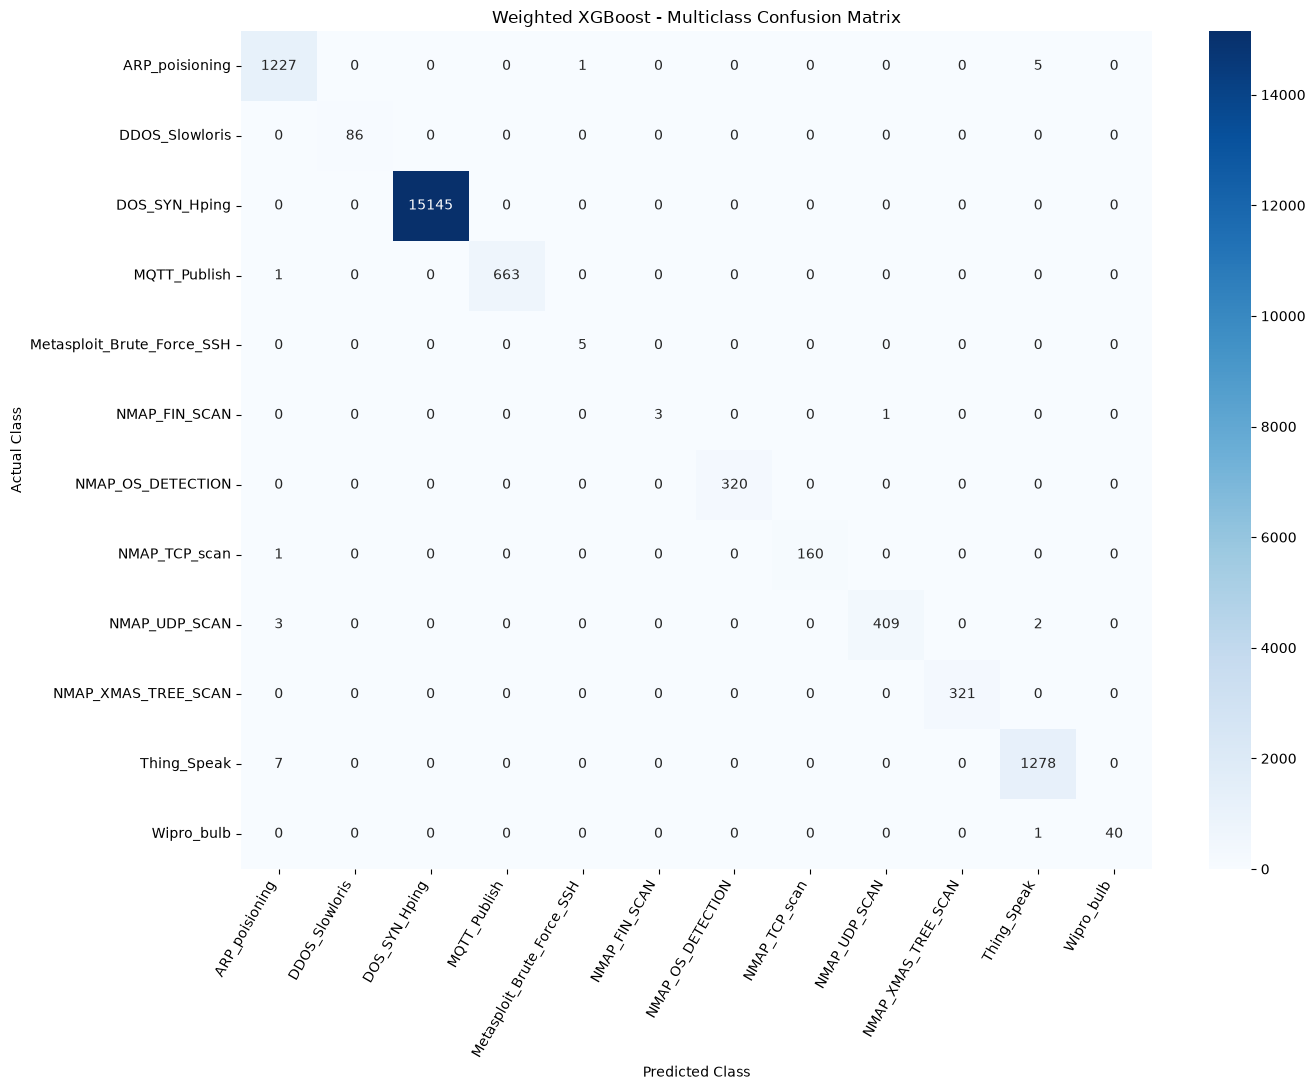

In [30]:
weighted_xgb_cm = confusion_matrix(
    y_val_encoded,
    weighted_xgb_predictions
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    weighted_xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Weighted XGBoost - Multiclass Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
pd.DataFrame([weighted_xgb_metrics]).to_csv(
    "../reports/metrics/multiclass_weighted_xgboost.csv",
    index=False
)

In [32]:
from sklearn.model_selection import StratifiedGroupKFold

# Identify identical feature groups within the training set
train_groups = pd.util.hash_pandas_object(
    X_train,
    index=False
).to_numpy()

# 3-fold stratified, group-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("Training samples:", len(X_train))
print("Unique feature groups:", len(np.unique(train_groups)))
print("Number of CV folds:", cv.get_n_splits())

Training samples: 78712
Unique feature groups: 75467
Number of CV folds: 3


In [33]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
import numpy as np


class WeightedXGBClassifier(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=1,
        gamma=0,
        reg_lambda=1,
        random_state=42,
        n_jobs=-1
    ):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.min_child_weight = min_child_weight
        self.gamma = gamma
        self.reg_lambda = reg_lambda
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        self.classes_ = np.unique(y)

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y
        )

        self.model_ = XGBClassifier(
            n_estimators=self.n_estimators,
            max_depth=self.max_depth,
            learning_rate=self.learning_rate,
            subsample=self.subsample,
            colsample_bytree=self.colsample_bytree,
            min_child_weight=self.min_child_weight,
            gamma=self.gamma,
            reg_lambda=self.reg_lambda,
            objective="multi:softprob",
            num_class=len(self.classes_),
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=self.random_state,
            n_jobs=self.n_jobs
        )

        self.model_.fit(
            X,
            y,
            sample_weight=sample_weights
        )

        return self

    def predict(self, X):
        return self.model_.predict(X)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

In [34]:
from sklearn.pipeline import Pipeline

weighted_xgb_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", WeightedXGBClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

print(weighted_xgb_tuning_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  SimpleImputer(strategy='median'),
                                                  ['id.orig_p', 'id.resp_p',
                                                   'flow_duration',
                                                   'fwd_pkts_tot',
                                                   'bwd_pkts_tot',
                                                   'fwd_data_pkts_tot',
                                                   'bwd_data_pkts_tot',
                                                   'fwd_pkts_per_sec',
                                                   'bwd_pkts_per_sec',
                                                   'flow_pkts_per_sec',
                                                   'down_up_ratio',
                                                   'fwd_header_size_tot',
                                         

In [35]:
from scipy.stats import randint, uniform, loguniform

param_distributions = {
    "model__n_estimators": randint(150, 501),
    "model__max_depth": randint(3, 10),
    "model__learning_rate": loguniform(0.02, 0.2),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.7, 0.3),
    "model__min_child_weight": randint(1, 8),
    "model__gamma": uniform(0, 2),
    "model__reg_lambda": loguniform(0.1, 10)
}

print("Number of hyperparameters:", len(param_distributions))

Number of hyperparameters: 8


In [36]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=weighted_xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="f1_macro",
    cv=cv,
    verbose=2,
    random_state=42,
    n_jobs=1,
    refit=True,
    return_train_score=True
)

print("Search configured successfully.")
print("Number of candidates:", 15)
print("CV folds:", 3)
print("Total model fits:", 15 * 3)
print("Optimization metric: Macro F1")

Search configured successfully.
Number of candidates: 15
CV folds: 3
Total model fits: 45
Optimization metric: Macro F1


In [37]:
import time

start_time = time.time()

random_search.fit(
    X_train,
    y_train_encoded,
    groups=train_groups
)

end_time = time.time()

print(f"Search completed in {(end_time - start_time) / 60:.2f} minutes")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV] END model__colsample_bytree=0.8123620356542087, model__gamma=1.9014286128198323, model__learning_rate=0.10790061933340454, model__max_depth=7, model__min_child_weight=5, model__n_estimators=252, model__reg_lambda=0.7792297153882993, model__subsample=0.7299924747454009; total time=  24.2s
[CV] END model__colsample_bytree=0.8123620356542087, model__gamma=1.9014286128198323, model__learning_rate=0.10790061933340454, model__max_depth=7, model__min_child_weight=5, model__n_estimators=252, model__reg_lambda=0.7792297153882993, model__subsample=0.7299924747454009; total time=  25.4s
[CV] END model__colsample_bytree=0.8123620356542087, model__gamma=1.9014286128198323, model__learning_rate=0.10790061933340454, model__max_depth=7, model__min_child_weight=5, model__n_estimators=252, model__reg_lambda=0.7792297153882993, model__subsample=0.7299924747454009; total time=  25.6s
[CV] END model__colsample_bytree=0.8377746675897602, mode

In [38]:
print("Best CV Macro F1:", random_search.best_score_)
print("\nBest parameters:")

for parameter, value in random_search.best_params_.items():
    print(f"{parameter}: {value}")

Best CV Macro F1: 0.9567523405978013

Best parameters:
model__colsample_bytree: 0.7637017332034828
model__gamma: 0.36364993441420124
model__learning_rate: 0.03050945891610522
model__max_depth: 6
model__min_child_weight: 2
model__n_estimators: 171
model__reg_lambda: 0.10330768043240408
model__subsample: 0.7069187275124247


In [39]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Best estimator was automatically refitted on full training data
tuned_xgb = random_search.best_estimator_

# Predict validation labels
tuned_xgb_predictions = tuned_xgb.predict(X_val)

# Calculate metrics
tuned_xgb_results = {
    "Model": "Tuned Weighted XGBoost",
    "Accuracy": accuracy_score(y_val_encoded, tuned_xgb_predictions),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val_encoded, tuned_xgb_predictions
    ),
    "Macro F1": f1_score(
        y_val_encoded, tuned_xgb_predictions, average="macro"
    ),
    "Weighted F1": f1_score(
        y_val_encoded, tuned_xgb_predictions, average="weighted"
    )
}

print("Tuned Weighted XGBoost - Validation Results")
print("-" * 50)

for metric, value in tuned_xgb_results.items():
    print(f"{metric}: {value:.6f}" if isinstance(value, float) else metric)

print("\nClassification Report:\n")

print(classification_report(
    y_val_encoded,
    tuned_xgb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Tuned Weighted XGBoost - Validation Results
--------------------------------------------------
Model
Accuracy: 0.998577
Balanced Accuracy: 0.974225
Macro F1: 0.976100
Weighted F1: 0.998576

Classification Report:

                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1233
            DDOS_Slowloris       1.00      1.00      1.00        86
             DOS_SYN_Hping       1.00      1.00      1.00     15145
              MQTT_Publish       1.00      1.00      1.00       664
Metasploit_Brute_Force_SSH       0.83      1.00      0.91         5
             NMAP_FIN_SCAN       1.00      0.75      0.86         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       320
             NMAP_TCP_scan       1.00      0.99      1.00       161
             NMAP_UDP_SCAN       1.00      0.99      0.99       414
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       321
               Thing_Speak       0.99

In [40]:
comparison = pd.DataFrame([
    {
        "Model": "Original Weighted XGBoost",
        "Accuracy": 0.998882,
        "Balanced Accuracy": 0.974625,
        "Macro F1": 0.977468,
        "Weighted F1": 0.998881
    },
    tuned_xgb_results
])

display(comparison.round(6))

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Original Weighted XGBoost,0.998882,0.974625,0.977468,0.998881
1,Tuned Weighted XGBoost,0.998577,0.974225,0.976100,0.998576


In [41]:
# Select the best model based on validation Macro F1
best_multiclass_model = weighted_xgb_pipeline

best_multiclass_model_name = "Original Weighted XGBoost"

print("Selected model:", best_multiclass_model_name)

Selected model: Original Weighted XGBoost


In [42]:
import os

os.makedirs("../reports/metrics", exist_ok=True)

comparison.to_csv(
    "../reports/metrics/multiclass_tuning_comparison.csv",
    index=False
)

print("Multiclass tuning comparison saved successfully.")

Multiclass tuning comparison saved successfully.


In [43]:
# Access the fitted XGBoost model
xgb_model = weighted_xgb_pipeline.named_steps["model"]

# Get transformed feature names from the fitted preprocessor
feature_names = (
    weighted_xgb_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract feature importance
importance_values = xgb_model.feature_importances_

# Create feature importance DataFrame
multiclass_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
multiclass_feature_importance = (
    multiclass_feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(multiclass_feature_importance.head(20))

,Feature,Importance
0,categorical__service_ssh,0.269924
1,categorical__service_mqtt,0.128865
2,categorical__service_http,0.070953
3,numerical__fwd_URG_flag_count,0.069788
4,numerical__flow_FIN_flag_count,0.051885
5,numerical__fwd_header_size_min,0.029150
6,numerical__fwd_header_size_tot,0.022354
7,categorical__service_dns,0.020524
8,numerical__fwd_data_pkts_tot,0.019973
9,numerical__bwd_pkts_payload.avg,0.018587


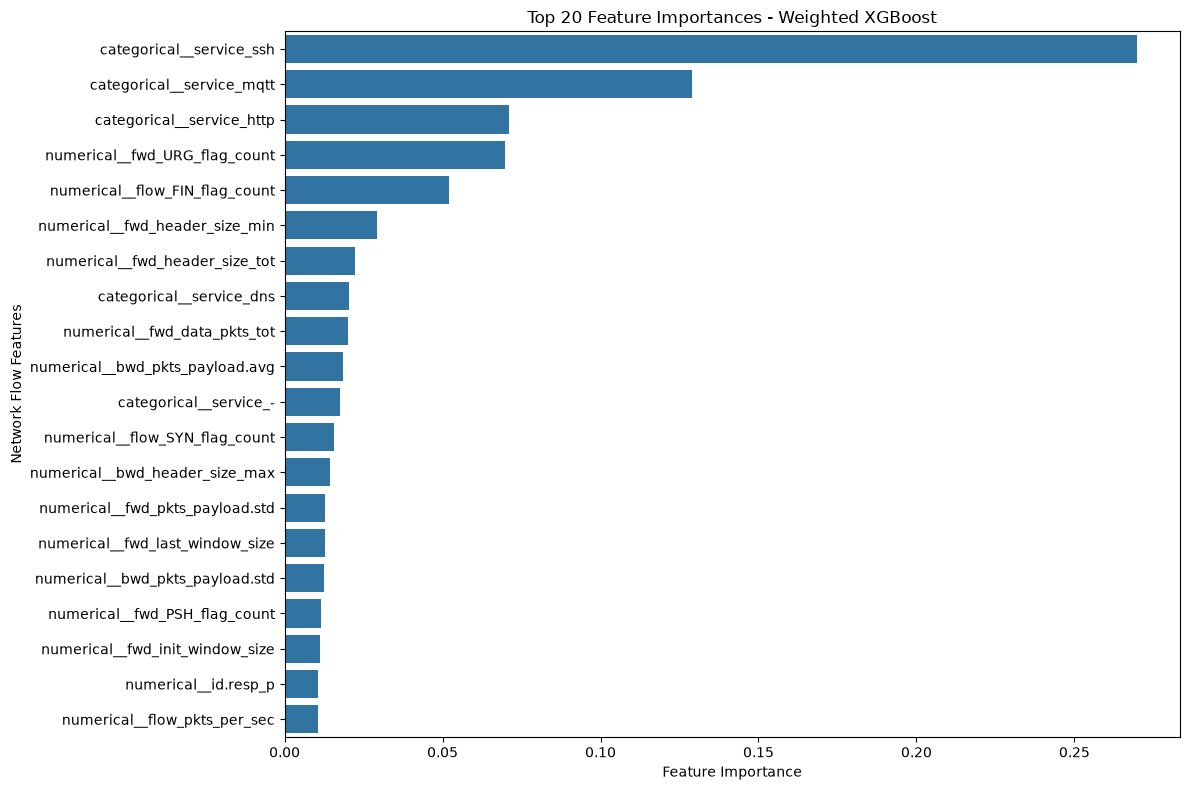

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

top_20_features = multiclass_feature_importance.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Feature Importances - Weighted XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Network Flow Features")
plt.tight_layout()
plt.show()

In [45]:
# Remove categorical features
X_train_no_cat = X_train.drop(columns=["proto", "service"])
X_val_no_cat = X_val.drop(columns=["proto", "service"])

# Numerical-only preprocessing
preprocessor_numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Train weighted XGBoost
numeric_only_pipeline = Pipeline([
    ("preprocessor", preprocessor_numeric),
    ("model", WeightedXGBClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

numeric_only_pipeline.fit(
    X_train_no_cat,
    y_train_encoded
)

# Validation predictions
numeric_only_predictions = numeric_only_pipeline.predict(
    X_val_no_cat
)

# Evaluate
numeric_only_results = {
    "Model": "Weighted XGBoost - Numerical Only",
    "Accuracy": accuracy_score(
        y_val_encoded, numeric_only_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val_encoded, numeric_only_predictions
    ),
    "Macro F1": f1_score(
        y_val_encoded, numeric_only_predictions, average="macro"
    ),
    "Weighted F1": f1_score(
        y_val_encoded, numeric_only_predictions, average="weighted"
    )
}

display(pd.DataFrame([numeric_only_results]).round(6))

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Weighted XGBoost - Numerical Only,0.998679,0.955663,0.967123,0.998675


In [46]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    weighted_xgb_pipeline,
    X_val,
    y_val_encoded,
    scoring="f1_macro",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
})

permutation_importance_df = (
    permutation_importance_df
    .sort_values("Importance_Mean", ascending=False)
    .reset_index(drop=True)
)

display(permutation_importance_df.head(20))

,Feature,Importance_Mean,Importance_Std
0,fwd_header_size_min,0.127805,0.000397
1,flow_iat.min,0.055557,0.001801
2,service,0.052531,0.002747
3,id.resp_p,0.041434,0.000974
4,id.orig_p,0.017097,0.002848
5,fwd_pkts_payload.min,0.012389,0.000377
6,idle.max,0.009865,0.002534
7,fwd_URG_flag_count,0.009504,0.000421
8,flow_iat.avg,0.009258,0.000000
9,active.min,0.007850,0.003259


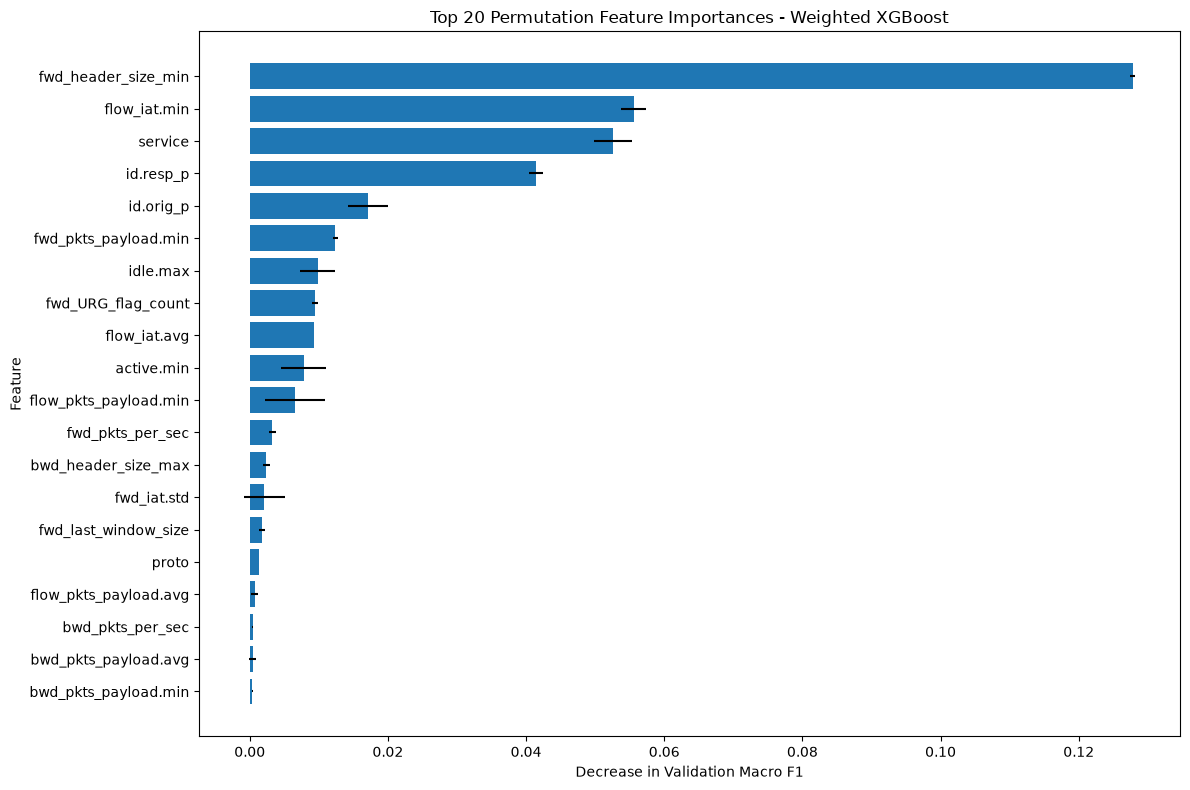

In [47]:
plt.figure(figsize=(12, 8))

top_features = permutation_importance_df.head(20).sort_values(
    "Importance_Mean",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"]
)

plt.title("Top 20 Permutation Feature Importances - Weighted XGBoost")
plt.xlabel("Decrease in Validation Macro F1")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

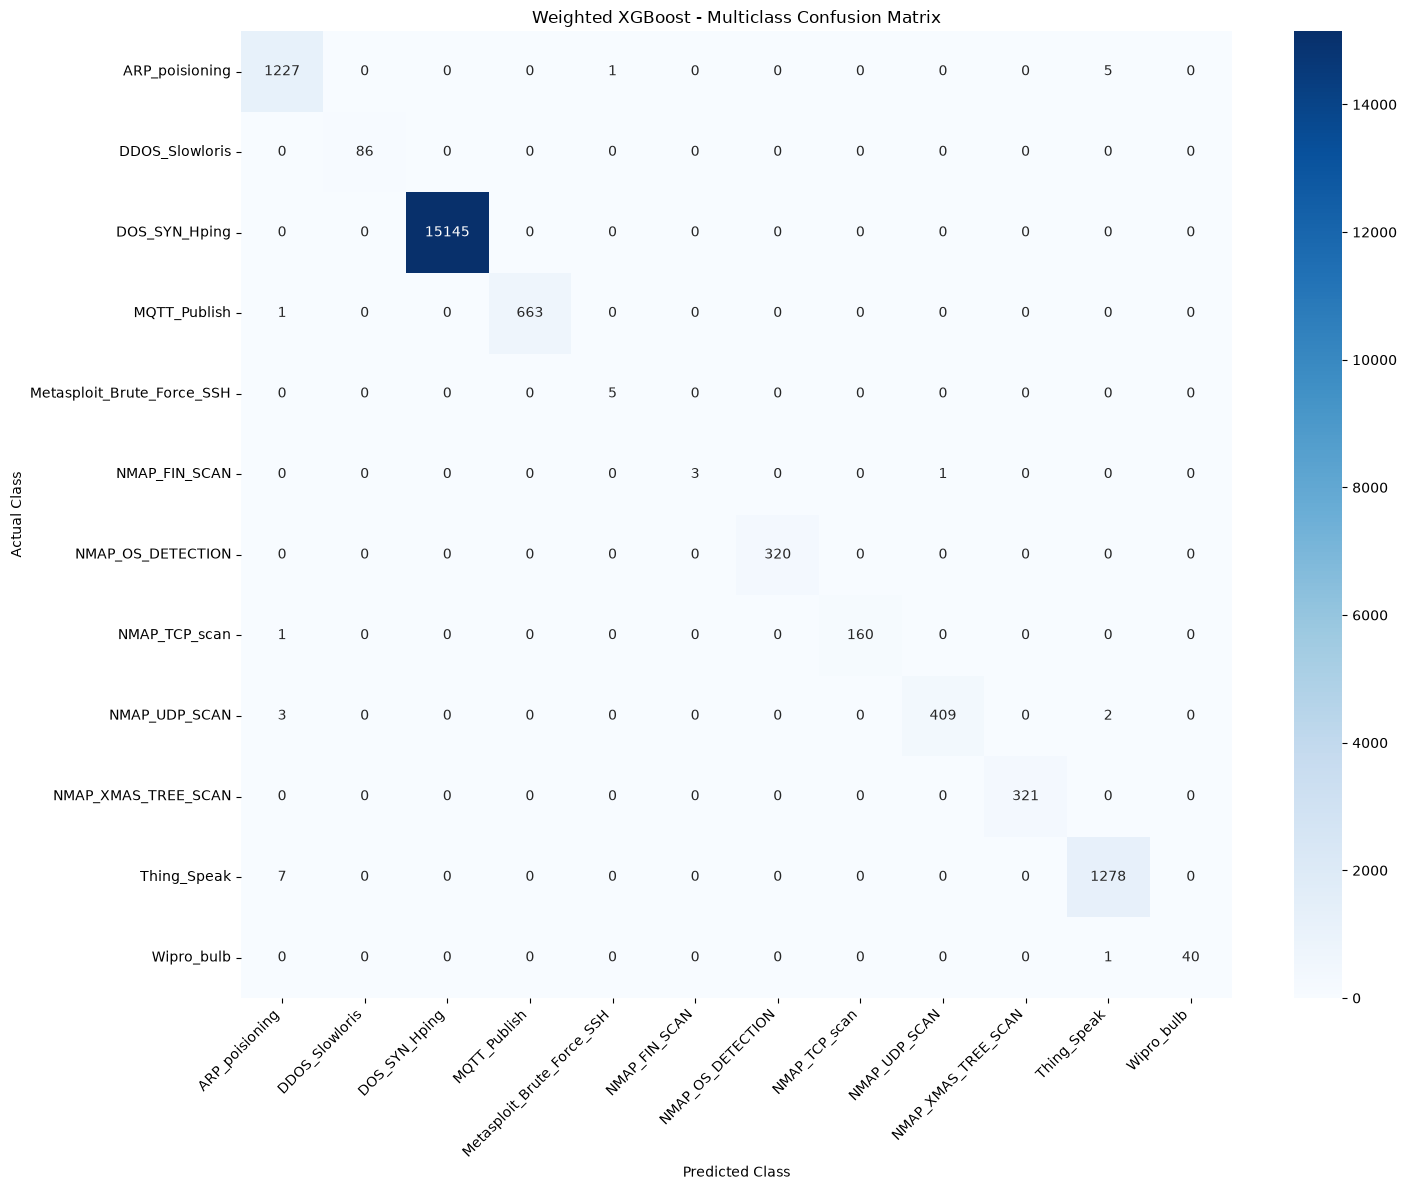

In [48]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_val_encoded,
    weighted_xgb_pipeline.predict(X_val),
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Weighted XGBoost - Multiclass Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [49]:
error_analysis = pd.DataFrame({
    "Actual_Class": label_encoder.classes_,
    "Support": np.bincount(y_val_encoded),
    "Correct_Predictions": np.diag(cm),
    "Misclassified": np.bincount(y_val_encoded) - np.diag(cm)
})

error_analysis["Recall"] = (
    error_analysis["Correct_Predictions"] /
    error_analysis["Support"]
)

display(
    error_analysis.sort_values(
        "Misclassified",
        ascending=False
    ).round(4)
)

,Actual_Class,Support,Correct_Predictions,Misclassified,Recall
10,Thing_Speak,1285,1278,7,0.9946
0,ARP_poisioning,1233,1227,6,0.9951
8,NMAP_UDP_SCAN,414,409,5,0.9879
3,MQTT_Publish,664,663,1,0.9985
11,Wipro_bulb,41,40,1,0.9756
7,NMAP_TCP_scan,161,160,1,0.9938
5,NMAP_FIN_SCAN,4,3,1,0.7500
1,DDOS_Slowloris,86,86,0,1.0000
2,DOS_SYN_Hping,15145,15145,0,1.0000
4,Metasploit_Brute_Force_SSH,5,5,0,1.0000


In [50]:
# Create error analysis dataframe
misclassified_indices = np.where(
    y_val_encoded != tuned_predictions
)[0] if False else np.where(
    y_val_encoded != weighted_xgb_predictions
)[0]

misclassified_records = X_val.iloc[
    misclassified_indices
].copy()

misclassified_records["Actual_Class"] = label_encoder.inverse_transform(
    y_val_encoded[misclassified_indices]
)

misclassified_records["Predicted_Class"] = label_encoder.inverse_transform(
    weighted_xgb_predictions[misclassified_indices]
)

print("Total misclassified records:", len(misclassified_records))

display(
    misclassified_records[
        ["Actual_Class", "Predicted_Class",
         "proto", "service", "id.orig_p", "id.resp_p",
         "fwd_header_size_min", "flow_iat.min"]
    ]
)

Total misclassified records: 22


,Actual_Class,Predicted_Class,proto,service,id.orig_p,id.resp_p,fwd_header_size_min,flow_iat.min
3566,MQTT_Publish,ARP_poisioning,tcp,-,34600,80,20,1.704931e+03
4523,Thing_Speak,ARP_poisioning,udp,dns,5353,5353,8,1.011014e+06
4675,Thing_Speak,ARP_poisioning,udp,dns,51506,53,8,2.887831e+05
4695,Thing_Speak,ARP_poisioning,udp,dns,58336,53,8,9.362197e+04
4742,Thing_Speak,ARP_poisioning,udp,dns,5353,5353,8,0.000000e+00
4841,Thing_Speak,ARP_poisioning,tcp,ssl,49809,443,20,1.788139e+01
5303,Thing_Speak,ARP_poisioning,udp,dns,5353,5353,8,1.013340e+06
6664,Thing_Speak,ARP_poisioning,udp,dns,49347,53,8,2.310276e+02
12381,Wipro_bulb,Thing_Speak,udp,dns,63247,53,8,1.002071e+05
12528,ARP_poisioning,Metasploit_Brute_Force_SSH,tcp,http,50454,80,32,5.888939e+01


In [51]:
weighted_xgb_predictions = weighted_xgb_pipeline.predict(X_val)

In [52]:
# Get prediction probabilities
validation_probabilities = weighted_xgb_pipeline.predict_proba(X_val)

# Actual and predicted class indices
actual_labels = y_val_encoded
predicted_labels = weighted_xgb_predictions

# Maximum prediction probability
max_confidence = validation_probabilities.max(axis=1)

# Create confidence analysis
confidence_analysis = misclassified_records.copy()

confidence_analysis["Confidence"] = max_confidence[misclassified_indices]

confidence_analysis["Actual_Probability"] = (
    validation_probabilities[
        misclassified_indices,
        actual_labels[misclassified_indices]
    ]
)

confidence_analysis["Predicted_Probability"] = (
    validation_probabilities[
        misclassified_indices,
        predicted_labels[misclassified_indices]
    ]
)

confidence_analysis["Confidence_Gap"] = (
    confidence_analysis["Predicted_Probability"] -
    confidence_analysis["Actual_Probability"]
)

display(
    confidence_analysis[
        [
            "Actual_Class",
            "Predicted_Class",
            "Confidence",
            "Actual_Probability",
            "Predicted_Probability",
            "Confidence_Gap"
        ]
    ].sort_values("Confidence", ascending=False).round(4)
)

,Actual_Class,Predicted_Class,Confidence,Actual_Probability,Predicted_Probability,Confidence_Gap
4742,Thing_Speak,ARP_poisioning,0.9982,0.0011,0.9982,0.9971
119705,NMAP_UDP_SCAN,ARP_poisioning,0.9958,0.0006,0.9958,0.9952
119706,NMAP_UDP_SCAN,ARP_poisioning,0.9958,0.0006,0.9958,0.9952
119987,NMAP_UDP_SCAN,ARP_poisioning,0.9841,0.0035,0.9841,0.9806
12381,Wipro_bulb,Thing_Speak,0.9736,0.0260,0.9736,0.9475
3566,MQTT_Publish,ARP_poisioning,0.9703,0.0008,0.9703,0.9695
6664,Thing_Speak,ARP_poisioning,0.9699,0.0191,0.9699,0.9508
4695,Thing_Speak,ARP_poisioning,0.9130,0.0860,0.9130,0.8270
4841,Thing_Speak,ARP_poisioning,0.9107,0.0848,0.9107,0.8259
18804,ARP_poisioning,Thing_Speak,0.8517,0.1473,0.8517,0.7044


In [53]:
import os
import joblib

os.makedirs("../artifacts", exist_ok=True)

# Save the selected complete pipeline
joblib.dump(
    weighted_xgb_pipeline,
    "../artifacts/multiclass_weighted_xgboost.joblib"
)

# Save label encoder
joblib.dump(
    label_encoder,
    "../artifacts/multiclass_label_encoder.joblib"
)

print("Multiclass model saved successfully.")

Multiclass model saved successfully.


In [54]:
# Load the saved model and label encoder
final_multiclass_model = joblib.load(
    "../artifacts/multiclass_weighted_xgboost.joblib"
)

final_label_encoder = joblib.load(
    "../artifacts/multiclass_label_encoder.joblib"
)

# Predict test labels
y_test_predictions = final_multiclass_model.predict(X_test)

print("Test predictions generated successfully.")
print("Test samples:", len(y_test))

Test predictions generated successfully.
Test samples: 24598


In [55]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    classification_report
)

final_multiclass_metrics = {
    "Accuracy": accuracy_score(y_test_encoded, y_test_predictions),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test_encoded, y_test_predictions
    ),
    "Macro Precision": precision_score(
        y_test_encoded, y_test_predictions, average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test_encoded, y_test_predictions, average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test_encoded, y_test_predictions, average="macro"
    ),
    "Weighted F1": f1_score(
        y_test_encoded, y_test_predictions, average="weighted"
    )
}

print("FINAL MULTICLASS TEST RESULTS")
print("-" * 45)

for metric, value in final_multiclass_metrics.items():
    print(f"{metric}: {value:.6f}")

FINAL MULTICLASS TEST RESULTS
---------------------------------------------
Accuracy: 0.998171
Balanced Accuracy: 0.963157
Macro Precision: 0.955007
Macro Recall: 0.963157
Macro F1: 0.955250
Weighted F1: 0.998195


In [56]:
print(classification_report(
    y_test_encoded,
    y_test_predictions,
    labels=np.arange(len(final_label_encoder.classes_)),
    target_names=final_label_encoder.classes_,
    zero_division=0
))

                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1541
            DDOS_Slowloris       0.96      0.98      0.97       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.55      0.86      0.67         7
             NMAP_FIN_SCAN       1.00      0.80      0.89         5
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      0.99      1.00       200
             NMAP_UDP_SCAN       1.00      0.98      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1606
                Wipro_bulb       0.98      0.96      0.97        51

                  accuracy                           1.00     24598
                 macro avg       0.96      0.9

In [57]:
final_metrics_df = pd.DataFrame([
    {
        "Model": "Original Weighted XGBoost",
        **final_multiclass_metrics
    }
])

final_metrics_df.to_csv(
    "../reports/metrics/multiclass_final_test_metrics.csv",
    index=False
)

display(final_metrics_df.round(6))

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Original Weighted XGBoost,0.998171,0.963157,0.955007,0.963157,0.95525,0.998195


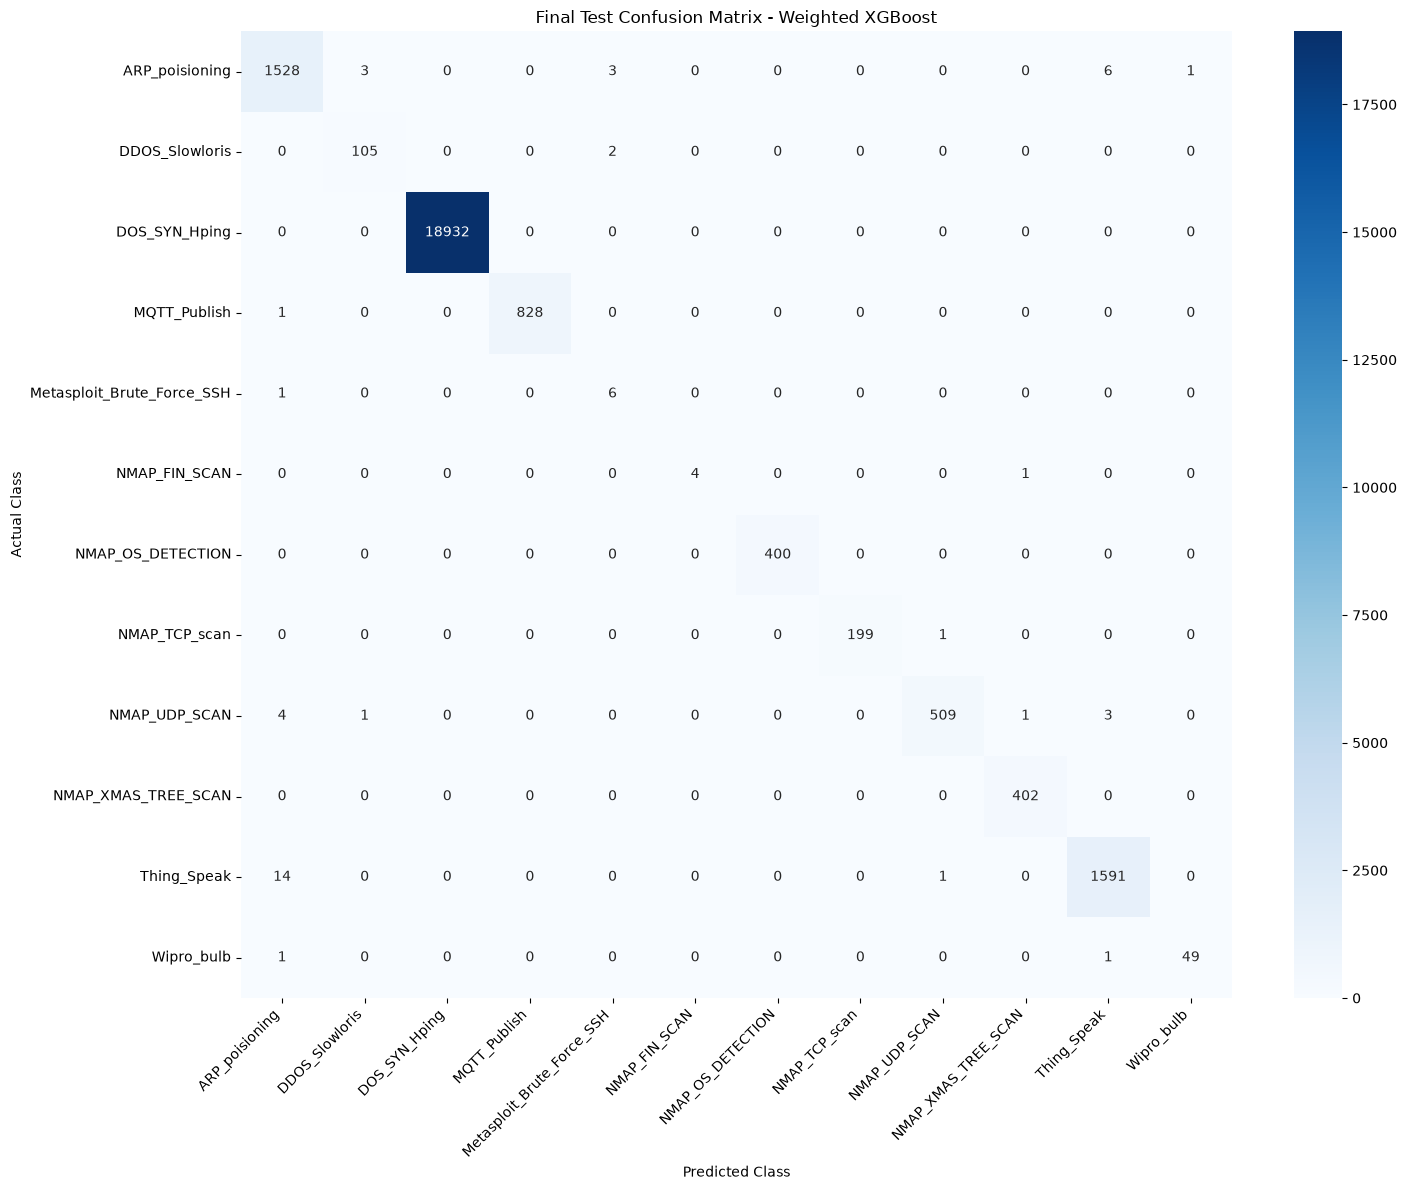

In [58]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

test_cm = confusion_matrix(
    y_test_encoded,
    y_test_predictions,
    labels=np.arange(len(final_label_encoder.classes_))
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=final_label_encoder.classes_,
    yticklabels=final_label_encoder.classes_
)

plt.title("Final Test Confusion Matrix - Weighted XGBoost")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../reports/figures/multiclass_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()